# 02 · Geometry → quality-index labels

Aligns the Tommerup (k=15) geometry campaigns and computes the track
quality index over time at the four sensor locations (m from the **switch-
blade tip**): A1, A2, A7, A11. Switch `cfg.geom_method` between `'std'` and
`'fractal'`.


In [1]:
import sys, os
from pathlib import Path
sys.path.insert(0, os.path.abspath('../src'))
import numpy as np, pandas as pd
from intelliswitch import Config, paths

# --- paths -----------------------------------------------------------------
# The project data lake (medallion tiers) is resolved by intelliswitch.paths, so
# it works regardless of the notebook's working dir and is overridable via the
# INTELLISWITCH_DATA_DIR / INTELLISWITCH_MODELS_DIR env vars.
RAW_CACHE = paths.RAW_CACHE       # data/interim/raw_cache  (decoded .npz, stage 1)
STORE     = paths.FEATURE_STORE   # data/processed/feature_store
MODELS    = paths.MODELS          # data/models
paths.ensure()                    # create the lake dirs if missing

# Raw source recordings (~7,800 logs) are large and live on the external drive;
# point DATA_ROOT at them, or symlink/copy the source into paths.RAW.
DATA_ROOT = Path(r"/Volumes/Seagate Expansion Drive/Mohammad/M Drive DTU/MATLAB Scripts/IntelliswitchScripts")
W10   = DATA_ROOT / "W10v140"       # vibration .log
BLADE = DATA_ROOT / "Bladenr8252"   # geometry .csv

cfg = Config()
cfg.freq_min_hz, cfg.freq_max_hz, cfg.geom_method, cfg.geom_sensor_locations_m

(10.0, 1000.0, 'std', (4.0, 9.0, 37.0, 50.0))

In [2]:
from intelliswitch.geometry import align_campaigns, build_deg_model

aligned = align_campaigns(BLADE, cfg)
deg = build_deg_model(aligned, cfg)
print('campaigns:', aligned.days.size,
      '| x range (m):', round(float(np.nanmin(aligned.x_blade_m)),1),
      '..', round(float(np.nanmax(aligned.x_blade_m)),1))
tbl = pd.DataFrame(deg.quality.T, columns=list(cfg.sensor_names))
tbl.insert(0, 'days', deg.days)
tbl


campaigns: 27 | x range (m): -63.8 .. 135.7


,days,A1,A2,A7,A11
0,-2495.0,-1.384285,-1.464921,-2.444335,-1.328568
1,-2383.0,-1.418271,-2.024667,-0.965916,-0.888816
2,-2297.0,-1.512283,-1.594177,-2.592102,-1.382206
3,-2232.0,-1.297989,-0.664530,-2.306269,-0.991839
4,-2124.0,-1.519762,-1.002173,-2.574393,-1.208495
5,-2022.0,-1.516825,-1.232555,-2.599779,-1.258015
6,-1940.0,-1.510779,-1.183784,-2.570241,-1.424060
7,-1861.0,-1.452650,-0.824742,-1.061294,-0.955088
8,-1774.0,-1.594569,-0.965972,-1.255929,-1.027798
9,-1683.0,-1.663704,-0.986925,-1.330165,-0.847285


### Quality index over time (lower = worse track)


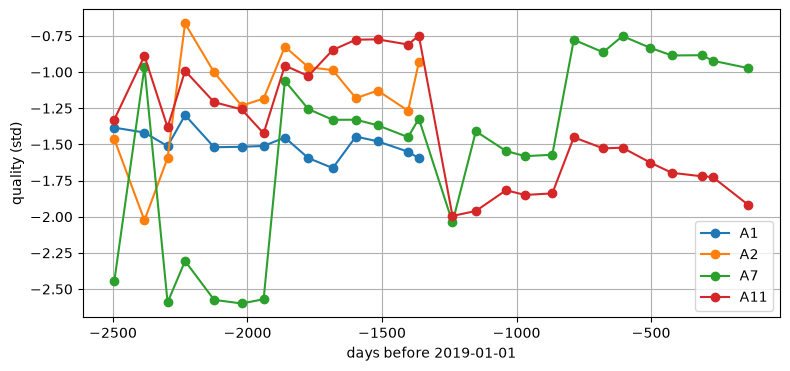

In [3]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9,4))
for i, name in enumerate(cfg.sensor_names):
    plt.plot(deg.days, deg.quality[i], '-o', label=name)
plt.xlabel('days before 2019-01-01'); plt.ylabel(f'quality ({cfg.geom_method})')
plt.legend(); plt.grid(True); plt.show()
